# Multi-Domain Incremental Learning: DARPA OpTC (Domain 0) $\rightarrow$ DARPA TC E3 THEIA (Domain 2)

Single-run Continual Learning pipeline implementing the verified Multi-Layer / Multi-Head / Progressive-Unfreeze / Experience-Replay architecture (`L=3` Causal Triplets `[E_incoming, E_parent, E_current]`):

1. **Expandable Layer + Multi-Head (`ExpandableMixHeadCausalIL`)**: Loads all **48/48 tensors** from OpTC checkpoint `mixhead_attention_t4x2_full.pt`, freezes base layers, and adds a new **4-head `TransformerCausalBlock` + L=3 residual multi-head branch** with zero-initialized gates (`max|Δlogits| == 0.0` vs OpTC Base at Epoch 0).
2. **Unified Label Taxonomy (Zero Task-ID Inference)**: Extends Scenario head `4 -> 6` and Stage head `10 -> 14` while preserving all OpTC classes `[0..3]` and `[0..9]` intact alongside THEIA `[4..5]` and `[10..13]`.
3. **Progressive Unfreezing (`A -> B -> C`)**: Phase A (`1..4`, new layer/heads/tokens only) $\rightarrow$ Phase B (`5..8`, unfreeze upper OpTC body @ `1e-4`) $\rightarrow$ Phase C (`9..12`, unfreeze lower body & OpTC embeddings @ `2e-5`).
4. **Experience Replay + LwF Logit Distillation**: Mixes real stratified OpTC training samples (`optc_replay_train.pt`) in every step with MSE distillation toward cached OpTC teacher logits.
5. **Dual-Domain Evaluation + Backward Transfer (`BWT`)**: Evaluates once on **THEIA Test (`114,577`)** AND streamed **Full OpTC Test (`1,249,689`)** before vs after IL, exporting metrics, confusion matrices, and decoded tracebacks into `/kaggle/working/theia_traceback_results.zip`.

In [1]:
import copy
import json
import math
import os
import random
import time
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    roc_auc_score,
)
from torch.utils.data import DataLoader, Dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
n_gpus = torch.cuda.device_count()
print(f"Device: {device} | GPUs available: {n_gpus}")
for i in range(n_gpus):
    print(f"  GPU {i}: {torch.cuda.get_device_name(i)}")

WORK_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./output_theia_il")
WORK_DIR.mkdir(parents=True, exist_ok=True)


def locate_inputs():
    search_roots = [
        Path("/kaggle/input"),
        Path("/mnt/SSD_Data/optc/IL/dataset_4-THEIA/output"),
        Path("/mnt/SSD_Data/optc/DL/code/output"),
        Path("."),
    ]
    shards_dir, ckpt_path, replay_dir, optc_test_dir = None, None, None, None

    def _scan(roots):
        nonlocal shards_dir, ckpt_path, replay_dir, optc_test_dir
        for root in roots:
            if not root.exists():
                continue
            if shards_dir is None:
                for mf in root.rglob("split_manifest.json"):
                    if (mf.parent / "extended_dl_vocab.json").is_file() and (mf.parent / "train").is_dir():
                        shards_dir = mf.parent
                        break
            if ckpt_path is None:
                for cf in root.rglob("mixhead_attention_t4x2_full.pt"):
                    ckpt_path = cf
                    break
            if replay_dir is None:
                for rf in root.rglob("optc_replay_train.pt"):
                    replay_dir = rf.parent
                    break
            if optc_test_dir is None:
                for od in root.rglob("optc_test_shards"):
                    if od.is_dir() and any(od.glob("shard_*.pt")):
                        optc_test_dir = od
                        break
                if optc_test_dir is None:
                    cand = root / "dl_shards/test"
                    if cand.is_dir() and (shards_dir is None or cand.parent.resolve() != shards_dir.resolve()):
                        if len(list(cand.glob("shard_*.pt"))) >= 100:
                            optc_test_dir = cand

    _scan(search_roots)
    if (shards_dir is None or optc_test_dir is None) and Path("/kaggle/input").exists():
        ext_dir = WORK_DIR / "_extracted_inputs"
        if not ext_dir.exists():
            for zf in Path("/kaggle/input").rglob("*.zip"):
                with zipfile.ZipFile(zf, "r") as z:
                    z.extractall(ext_dir)
        _scan([ext_dir])

    assert shards_dir is not None, "Missing THEIA shards directory"
    assert ckpt_path is not None, "Missing OpTC mixhead_attention_t4x2_full.pt"
    assert replay_dir is not None, "Missing optc_il_eval/ (optc_replay_train.pt)"
    assert optc_test_dir is not None, "Missing optc_test_shards/ for OpTC backward evaluation"
    assert len(list(optc_test_dir.glob("shard_*.pt"))) >= 100, f"Unexpected OpTC test dir {optc_test_dir} (<100 shards)"
    return shards_dir, ckpt_path, replay_dir, optc_test_dir


SHARDS_DIR, OPTC_CKPT_PATH, REPLAY_DIR, OPTC_TEST_DIR = locate_inputs()
print(f"Resolved THEIA SHARDS_DIR : {SHARDS_DIR}")
print(f"Resolved OPTC CKPT        : {OPTC_CKPT_PATH}")
print(f"Resolved OPTC REPLAY_DIR  : {REPLAY_DIR}")
print(f"Resolved OPTC_TEST_DIR    : {OPTC_TEST_DIR} ({len(list(OPTC_TEST_DIR.glob('shard_*.pt')))} shards)")

with open(SHARDS_DIR / "split_manifest.json", "r", encoding="utf-8") as f:
    MANIFEST = json.load(f)
with open(SHARDS_DIR / "extended_dl_vocab.json", "r", encoding="utf-8") as f:
    VOCAB = json.load(f)
ID2TOK = {int(v): k for k, v in VOCAB.items()}

BASE_VOCAB_SIZE = int(MANIFEST.get("base_vocab_size", 10499))
TOTAL_VOCAB_SIZE = len(VOCAB)

OPTC_SCENARIO_NAMES = {
    0: "Benign",
    1: "OpTC_SC1_EmpireStaging",
    2: "OpTC_SC2_CustomEmpireLateral",
    3: "OpTC_SC3_MaliciousUpdate",
}
OPTC_STAGE_NAMES = {
    0: "Benign",
    1: "OpTC_Execution",
    2: "OpTC_Defense_Evasion_Injection",
    3: "OpTC_Defense_Evasion_AMSI",
    4: "OpTC_Discovery",
    5: "OpTC_Credential_Access",
    6: "OpTC_Lateral_Movement",
    7: "OpTC_Persistence",
    8: "OpTC_Command_and_Control",
    9: "OpTC_Collection_Exfiltration",
}
THEIA_SCENARIO_OFFSET = 3
THEIA_STAGE_OFFSET = 9
UNIFIED_SCENARIO_NAMES = {
    **OPTC_SCENARIO_NAMES,
    4: "THEIA_NationState_Firefox_Drakon",
    5: "THEIA_BrowserExtension_MicroAPT",
}
UNIFIED_STAGE_NAMES = {
    **OPTC_STAGE_NAMES,
    10: "THEIA_Initial_Compromise",
    11: "THEIA_Execution_PrivilegeEscalation",
    12: "THEIA_Discovery_Reconnaissance",
    13: "THEIA_C2_Exfiltration",
}
print(f"Vocab: OpTC base={BASE_VOCAB_SIZE}, total={TOTAL_VOCAB_SIZE} | Unified classes: {len(UNIFIED_SCENARIO_NAMES)} scenarios, {len(UNIFIED_STAGE_NAMES)} stages")

Device: cuda | GPUs available: 2
  GPU 0: Tesla T4
  GPU 1: Tesla T4
Resolved THEIA SHARDS_DIR : /kaggle/input/datasets/ngkimngn/dl-il-theia/theia_dl_shards
Resolved OPTC CKPT        : /kaggle/input/datasets/ngkimngn/dl-il-theia/mixhead_attention_t4x2_full.pt
Resolved OPTC REPLAY_DIR  : /kaggle/input/datasets/ngkimngn/dl-il-theia/optc_il_eval
Resolved OPTC_TEST_DIR    : /kaggle/input/datasets/ngkimngn/dl-il-theia/optc_test_shards (125 shards)
Vocab: OpTC base=10499, total=20937 | Unified classes: 6 scenarios, 14 stages


In [2]:
def map_theia_labels_to_unified(samples):
    mapped = []
    for s in samples:
        sc = int(s["scenario_id"])
        st = int(s["stage_id"])
        u_sc = (sc + THEIA_SCENARIO_OFFSET) if sc > 0 else 0
        u_st = (st + THEIA_STAGE_OFFSET) if st > 0 else 0
        mapped.append({
            **s,
            "is_malicious": int(s["is_malicious"]),
            "scenario_id": u_sc,
            "stage_id": u_st,
            "is_optc": 0,
        })
    return mapped


class UnifiedSampleDataset(Dataset):
    def __init__(self, samples):
        self.samples = samples

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        return self.samples[idx]


def load_theia_split(split_name: str):
    files = sorted((SHARDS_DIR / split_name).glob("shard_*.pt"))
    raw = []
    for sf in files:
        raw.extend(torch.load(sf, map_location="cpu", weights_only=False))
    mapped = map_theia_labels_to_unified(raw)
    print(f"Loaded THEIA {split_name:5s}: {len(mapped):,} samples from {len(files)} shards")
    return mapped


def pad_triplets(batch):
    """Pad L=3 causal triplets into `(B, 3, max_len)` for DataParallel multi-GPU execution."""
    b = len(batch)
    max_len = 1
    labels_bin, labels_sc, labels_st, is_optc = [], [], [], []
    t_bin, t_sc, t_st = [], [], []
    has_teacher = any("t_bin" in s for s in batch)
    triplets = []

    for s in batch:
        labels_bin.append(float(s["is_malicious"]))
        labels_sc.append(int(s["scenario_id"]))
        labels_st.append(int(s["stage_id"]))
        is_optc.append(int(s.get("is_optc", 0)))
        if has_teacher:
            t_bin.append(float(s.get("t_bin", 0.0)))
            t_sc.append(s.get("t_sc", [0.0] * 4))
            t_st.append(s.get("t_st", [0.0] * 10))
        row = []
        for k in ("incoming_ids", "parent_ids", "current_ids"):
            ids = s.get(k) or [2]
            if not ids:
                ids = [2]
            if len(ids) > max_len:
                max_len = len(ids)
            row.append(ids)
        triplets.append(row)

    token_ids = torch.zeros((b, 3, max_len), dtype=torch.long)
    for i, row in enumerate(triplets):
        for li, ids in enumerate(row):
            token_ids[i, li, :len(ids)] = torch.tensor(ids, dtype=torch.long)

    out = {
        "token_ids": token_ids,
        "target_binary": torch.tensor(labels_bin, dtype=torch.float32),
        "target_scenario": torch.tensor(labels_sc, dtype=torch.long),
        "target_stage": torch.tensor(labels_st, dtype=torch.long),
        "is_optc": torch.tensor(is_optc, dtype=torch.bool),
    }
    if has_teacher:
        out["teacher_bin"] = torch.tensor(t_bin, dtype=torch.float32)
        out["teacher_sc"] = torch.tensor(t_sc, dtype=torch.float32)
        out["teacher_st"] = torch.tensor(t_st, dtype=torch.float32)
    return out


theia_train_samples = load_theia_split("train")
theia_val_samples = load_theia_split("val")
theia_test_samples = load_theia_split("test")

optc_replay_samples = [
    {**s, "is_optc": 1, "t_bin": 0.0, "t_sc": [0.0] * 4, "t_st": [0.0] * 10}
    for s in torch.load(REPLAY_DIR / "optc_replay_train.pt", map_location="cpu", weights_only=False)
]
optc_val_samples = [
    {**s, "is_optc": 1}
    for s in torch.load(REPLAY_DIR / "optc_val_eval.pt", map_location="cpu", weights_only=False)
]
print(f"Loaded OpTC Replay Train: {len(optc_replay_samples):,} samples | OpTC Val Eval: {len(optc_val_samples):,} samples")

BATCH_SIZE = 512 if torch.cuda.is_available() else 256
theia_val_loader = DataLoader(UnifiedSampleDataset(theia_val_samples), batch_size=BATCH_SIZE, shuffle=False, collate_fn=pad_triplets, num_workers=2, pin_memory=True)
theia_test_loader = DataLoader(UnifiedSampleDataset(theia_test_samples), batch_size=BATCH_SIZE, shuffle=False, collate_fn=pad_triplets, num_workers=2, pin_memory=True)
optc_val_loader = DataLoader(UnifiedSampleDataset(optc_val_samples), batch_size=BATCH_SIZE, shuffle=False, collate_fn=pad_triplets, num_workers=2, pin_memory=True)

train_sc_cnt = Counter(int(s["scenario_id"]) for s in theia_train_samples)
train_st_cnt = Counter(int(s["stage_id"]) for s in theia_train_samples)
print("THEIA Train unified scenario counts:", dict(sorted(train_sc_cnt.items())))
print("THEIA Train unified stage counts   :", dict(sorted(train_st_cnt.items())))

Loaded THEIA train: 408,633 samples from 41 shards
Loaded THEIA val  : 56,838 samples from 6 shards
Loaded THEIA test : 114,577 samples from 12 shards
Loaded OpTC Replay Train: 100,000 samples | OpTC Val Eval: 50,000 samples
THEIA Train unified scenario counts: {0: 361312, 4: 1114, 5: 46207}
THEIA Train unified stage counts   : {0: 361312, 10: 551, 11: 82, 12: 46467, 13: 221}


In [3]:
class PeterBloemMultiHeadSelfAttention(nn.Module):
    def __init__(self, embed_dim: int = 128, num_heads: int = 4, dropout: float = 0.1):
        super().__init__()
        assert embed_dim % num_heads == 0
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.to_keys = nn.Linear(embed_dim, embed_dim, bias=False)
        self.to_queries = nn.Linear(embed_dim, embed_dim, bias=False)
        self.to_values = nn.Linear(embed_dim, embed_dim, bias=False)
        self.unify_heads = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor):
        b, t, d = x.size()
        h, s = self.num_heads, self.head_dim
        queries = self.to_queries(x).view(b, t, h, s).transpose(1, 2)
        keys = self.to_keys(x).view(b, t, h, s).transpose(1, 2)
        values = self.to_values(x).view(b, t, h, s).transpose(1, 2)
        scores = torch.matmul(queries, keys.transpose(-2, -1)) / math.sqrt(s)
        attn_weights = F.softmax(scores, dim=-1)
        out = torch.matmul(self.dropout(attn_weights), values).transpose(1, 2).contiguous().view(b, t, d)
        return self.unify_heads(out), attn_weights


class TransformerCausalBlock(nn.Module):
    def __init__(self, embed_dim: int = 128, num_heads: int = 4, ff_dim: int = 256, dropout: float = 0.1):
        super().__init__()
        self.attention = PeterBloemMultiHeadSelfAttention(embed_dim, num_heads=num_heads, dropout=dropout)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.ffn = nn.Sequential(
            nn.Linear(embed_dim, ff_dim), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(ff_dim, embed_dim), nn.Dropout(dropout),
        )

    def forward(self, x: torch.Tensor):
        attn_out, weights = self.attention(x)
        x = self.norm1(x + attn_out)
        x = self.norm2(x + self.ffn(x))
        return x, weights


class IncrementalLearningAdapter(nn.Module):
    def __init__(self, embed_dim: int = 128, bottleneck_dim: int = 32, dropout: float = 0.1):
        super().__init__()
        self.down_proj = nn.Linear(embed_dim, bottleneck_dim)
        self.act = nn.GELU()
        self.up_proj = nn.Linear(bottleneck_dim, embed_dim)
        self.norm = nn.LayerNorm(embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor):
        out = self.up_proj(self.dropout(self.act(self.down_proj(x))))
        return self.norm(x + out)


class MixHeadOpTCBase(nn.Module):
    """Exact OpTC Domain-0 reference model (48/48 state_dict parity)."""

    def __init__(self, vocab_size: int = 10599, embed_dim: int = 128, num_heads: int = 4, ff_dim: int = 256, num_blocks: int = 2, dropout: float = 0.1):
        super().__init__()
        self.embed_dim = embed_dim
        self.token_embedding = nn.EmbeddingBag(vocab_size, embed_dim, mode="mean", padding_idx=0)
        self.token_norm = nn.LayerNorm(embed_dim)
        self.line_embedding = nn.Embedding(3, embed_dim)
        self.blocks = nn.ModuleList([TransformerCausalBlock(embed_dim, num_heads, ff_dim, dropout) for _ in range(num_blocks)])
        self.il_adapter = IncrementalLearningAdapter(embed_dim, 32, dropout)
        self.line_pooling_attn = nn.Linear(embed_dim, 1)
        pooled_dim = embed_dim * 2
        self.binary_head = nn.Sequential(nn.Linear(pooled_dim, 64), nn.GELU(), nn.Dropout(dropout), nn.Linear(64, 1))
        self.scenario_head = nn.Sequential(nn.Linear(pooled_dim, 64), nn.GELU(), nn.Dropout(dropout), nn.Linear(64, 4))
        self.stage_head = nn.Sequential(nn.Linear(pooled_dim, 64), nn.GELU(), nn.Dropout(dropout), nn.Linear(64, 10))

    def forward_base_features(self, token_ids: torch.Tensor):
        b, n_lines, l_max = token_ids.shape
        x = self.token_norm(self.token_embedding(token_ids.reshape(b * n_lines, l_max))).view(b, n_lines, self.embed_dim)
        line_ids = torch.tensor([0, 1, 2], device=x.device).unsqueeze(0).expand(b, -1)
        x = x + self.line_embedding(line_ids)
        attn_maps = []
        for block in self.blocks:
            x, w = block(x)
            attn_maps.append(w)
        x = self.il_adapter(x)
        w_base = F.softmax(self.line_pooling_attn(x), dim=1)
        h_base = torch.cat([(x * w_base).sum(dim=1), x[:, 2, :]], dim=-1)
        return x, h_base, attn_maps, w_base.squeeze(-1)

    def forward(self, token_ids: torch.Tensor):
        _, h_base, attn_maps, lw = self.forward_base_features(token_ids)
        return {
            "binary_logits": self.binary_head(h_base).squeeze(-1),
            "scenario_logits": self.scenario_head(h_base),
            "stage_logits": self.stage_head(h_base),
            "attention_maps": attn_maps,
            "line_weights": lw,
        }


class ExpandableMixHeadCausalIL(MixHeadOpTCBase):
    """Multi-Layer + Multi-Head Domain-Incremental Extension (`OpTC -> THEIA`).

    Preserves 100% of OpTC base layers & heads (`0..3` scenarios, `0..9` stages) and adds a new
    4-head `TransformerCausalBlock` (`domain_blocks`) running over all 3 causal lines, plus a
    3-line-aware residual Multi-Head module gated by zero-initialized `gate_bin/gate_sc/gate_st`.
    At Epoch 0, outputs match `MixHeadOpTCBase` exactly (`max diff == 0.0`).
    """

    def __init__(self, vocab_size: int, embed_dim: int = 128, num_heads: int = 4, ff_dim: int = 256, num_blocks: int = 2, num_scenarios: int = 6, num_stages: int = 14, dropout: float = 0.1):
        super().__init__(vocab_size=vocab_size, embed_dim=embed_dim, num_heads=num_heads, ff_dim=ff_dim, num_blocks=num_blocks, dropout=dropout)
        self.num_scenarios = num_scenarios
        self.num_stages = num_stages

        # Added Layer for Dataset 2 (THEIA): new TransformerCausalBlock over L=3 lines
        self.domain_blocks = nn.ModuleList([TransformerCausalBlock(embed_dim, num_heads, ff_dim, dropout)])
        self.domain_norm = nn.LayerNorm(embed_dim)
        self.domain_pooling_attn = nn.Linear(embed_dim, 1)

        # Concat [domain_pooled, line0 (E_incoming), line1 (E_parent), line2 (E_current)] = 512-dim
        dom_dim = embed_dim * 4
        self.delta_binary_head = nn.Sequential(nn.Linear(dom_dim, 64), nn.GELU(), nn.Dropout(dropout), nn.Linear(64, 1))
        self.delta_scenario_head = nn.Sequential(nn.Linear(dom_dim, 64), nn.GELU(), nn.Dropout(dropout), nn.Linear(64, num_scenarios))
        self.delta_stage_head = nn.Sequential(nn.Linear(dom_dim, 64), nn.GELU(), nn.Dropout(dropout), nn.Linear(64, num_stages))

        # Residual gates initialized at 0.0 -> exact identity to OpTC base model before training
        self.gate_bin = nn.Parameter(torch.zeros(()))
        self.gate_sc = nn.Parameter(torch.zeros(()))
        self.gate_st = nn.Parameter(torch.zeros(()))

    def param_groups(self):
        base_upper, base_lower, new_params = [], [], []
        for name, p in self.named_parameters():
            if name.startswith(("domain_", "delta_", "gate_")):
                new_params.append(p)
            elif name == "token_embedding.weight":
                # Handled via row-wise gradient scaling/masking (`[:10499]` vs `[10499:]`)
                new_params.append(p)
            elif name.startswith(("blocks.1.", "il_adapter.", "line_pooling_attn.", "binary_head.", "scenario_head.", "stage_head.")):
                base_upper.append(p)
            else:
                base_lower.append(p)  # blocks.0., token_norm., line_embedding.
        return {"new": new_params, "base_upper": base_upper, "base_lower": base_lower}

    def forward(self, token_ids: torch.Tensor):
        x_base, h_base, attn_maps, lw_base = self.forward_base_features(token_ids)
        z_bin_base = self.binary_head(h_base).squeeze(-1)
        z_sc_base = self.scenario_head(h_base)
        z_st_base = self.stage_head(h_base)

        # Extended domain block across all 3 lines [E_incoming, E_parent, E_current]
        x_dom = x_base
        for blk in self.domain_blocks:
            x_dom, w_dom = blk(x_dom)
            attn_maps.append(w_dom)
        x_dom = self.domain_norm(x_dom)
        w_dom_pool = F.softmax(self.domain_pooling_attn(x_dom), dim=1)
        pooled_dom = (x_dom * w_dom_pool).sum(dim=1)
        h_dom = torch.cat([pooled_dom, x_dom[:, 0, :], x_dom[:, 1, :], x_dom[:, 2, :]], dim=-1)

        binary_logits = z_bin_base + self.gate_bin * self.delta_binary_head(h_dom).squeeze(-1)

        sc_pad_fill = z_sc_base.min(dim=-1, keepdim=True).values - 5.0
        sc_ext_base = torch.cat([z_sc_base, sc_pad_fill.expand(-1, self.num_scenarios - 4)], dim=-1)
        scenario_logits = sc_ext_base + self.gate_sc * self.delta_scenario_head(h_dom)

        st_pad_fill = z_st_base.min(dim=-1, keepdim=True).values - 5.0
        st_ext_base = torch.cat([z_st_base, st_pad_fill.expand(-1, self.num_stages - 10)], dim=-1)
        stage_logits = st_ext_base + self.gate_st * self.delta_stage_head(h_dom)

        return {
            "binary_logits": binary_logits,
            "scenario_logits": scenario_logits,
            "stage_logits": stage_logits,
            "attention_maps": attn_maps,
            "line_weights": lw_base,
        }


ckpt = torch.load(OPTC_CKPT_PATH, map_location="cpu", weights_only=False)
arch = ckpt["arch"]
CKPT_VOCAB_ROWS = int(ckpt.get("vocab_size", BASE_VOCAB_SIZE))
MODEL_VOCAB_SIZE = max(TOTAL_VOCAB_SIZE + 32, int(ckpt.get("model_vocab_size", 10599)))

teacher_base = MixHeadOpTCBase(
    vocab_size=int(ckpt.get("model_vocab_size", 10599)),
    embed_dim=int(arch["embed_dim"]),
    num_heads=int(arch["num_heads"]),
    ff_dim=int(arch["ff_dim"]),
    num_blocks=int(arch["num_transformer_blocks"]),
    dropout=0.1,
)
teacher_base.load_state_dict(ckpt["model_state_dict"], strict=True)
teacher_base = teacher_base.to(device).eval()
for p in teacher_base.parameters():
    p.requires_grad = False

base_model = ExpandableMixHeadCausalIL(
    vocab_size=MODEL_VOCAB_SIZE,
    embed_dim=int(arch["embed_dim"]),
    num_heads=int(arch["num_heads"]),
    ff_dim=int(arch["ff_dim"]),
    num_blocks=int(arch["num_transformer_blocks"]),
    num_scenarios=len(UNIFIED_SCENARIO_NAMES),
    num_stages=len(UNIFIED_STAGE_NAMES),
    dropout=0.1,
)
with torch.no_grad():
    nn.init.normal_(base_model.token_embedding.weight, mean=0.0, std=0.02)
    base_model.token_embedding.weight[0].zero_()
    sd = ckpt["model_state_dict"]
    own = base_model.state_dict()
    loaded_keys = 0
    for k, v in sd.items():
        if k == "token_embedding.weight":
            n_copy = min(v.shape[0], own[k].shape[0])
            own[k][:n_copy].copy_(v[:n_copy])
            loaded_keys += 1
        elif k in own and own[k].shape == v.shape:
            own[k].copy_(v)
            loaded_keys += 1
    assert loaded_keys == len(sd), f"Expected all {len(sd)} base tensors loaded, got {loaded_keys}"

print(f"Loaded ALL {loaded_keys}/{len(sd)} tensors from OpTC Domain-0 checkpoint into ExpandableMixHeadCausalIL!")
base_model = base_model.to(device)
model = nn.DataParallel(base_model) if n_gpus > 1 else base_model
raw_model = model.module if isinstance(model, nn.DataParallel) else model
FROZEN_BASE_EMB = raw_model.token_embedding.weight[:CKPT_VOCAB_ROWS].detach().clone().to(device)

# Mandatory Epoch-0 Equivalence Check (per `train_il.py` / `train_il_step3.py`)
teacher_eval_model = nn.DataParallel(teacher_base) if n_gpus > 1 else teacher_base
model.eval()
with torch.no_grad():
    b_o = next(iter(optc_val_loader))["token_ids"].to(device)
    o_il, o_te = model(b_o), teacher_eval_model(b_o)
    diff_optc_bin = float((o_il["binary_logits"] - o_te["binary_logits"]).abs().max())
    diff_optc_sc = float((o_il["scenario_logits"][:, :4] - o_te["scenario_logits"]).abs().max())
    diff_optc_st = float((o_il["stage_logits"][:, :10] - o_te["stage_logits"]).abs().max())
    print(f"Init Equivalence Check on OpTC Val -> bin={diff_optc_bin:.2e}, sc={diff_optc_sc:.2e}, st={diff_optc_st:.2e}")
    assert max(diff_optc_bin, diff_optc_sc, diff_optc_st) < 1e-4, "Epoch-0 identity check failed!"

# Cache exact frozen teacher logits for OpTC Replay Training (LwF / DER++ distillation targets)
t_cache_t0 = time.time()
rep_loader_tmp = DataLoader(UnifiedSampleDataset(optc_replay_samples), batch_size=BATCH_SIZE, shuffle=False, collate_fn=pad_triplets, num_workers=2)
t_bins, t_scs, t_sts = [], [], []
with torch.no_grad():
    for rb in rep_loader_tmp:
        tout = teacher_eval_model(rb["token_ids"].to(device, non_blocking=True))
        t_bins.append(tout["binary_logits"].cpu())
        t_scs.append(tout["scenario_logits"].cpu())
        t_sts.append(tout["stage_logits"].cpu())
t_bins = torch.cat(t_bins).tolist()
t_scs = torch.cat(t_scs).tolist()
t_sts = torch.cat(t_sts).tolist()
for idx, s in enumerate(optc_replay_samples):
    s["t_bin"] = t_bins[idx]
    s["t_sc"] = t_scs[idx]
    s["t_st"] = t_sts[idx]
print(f"Cached OpTC teacher logits for {len(optc_replay_samples):,} replay samples in {time.time() - t_cache_t0:.2f}s.")

Loaded ALL 50/50 tensors from OpTC Domain-0 checkpoint into ExpandableMixHeadCausalIL!
Init Equivalence Check on OpTC Val -> bin=0.00e+00, sc=0.00e+00, st=0.00e+00
Cached OpTC teacher logits for 100,000 replay samples in 5.44s.


In [4]:
def compute_eval_metrics(loader, eval_model, domain_mode: str = "theia", collect_outputs: bool = False):
    eval_model.eval()
    all_bp, all_bt, all_scp, all_sct, all_stp, all_stt = [], [], [], [], [], []
    with torch.no_grad():
        for b in loader:
            tids = b["token_ids"].to(device, non_blocking=True)
            out = eval_model(tids)
            all_bp.append(torch.sigmoid(out["binary_logits"]).cpu().numpy())
            all_bt.append(b["target_binary"].numpy())
            all_scp.append(out["scenario_logits"].argmax(dim=-1).cpu().numpy())
            all_sct.append(b["target_scenario"].numpy())
            all_stp.append(out["stage_logits"].argmax(dim=-1).cpu().numpy())
            all_stt.append(b["target_stage"].numpy())

    bp = np.concatenate(all_bp)
    bt = np.concatenate(all_bt).astype(int)
    scp = np.concatenate(all_scp)
    sct = np.concatenate(all_sct).astype(int)
    stp = np.concatenate(all_stp)
    stt = np.concatenate(all_stt).astype(int)

    sc_labels = [0, 4, 5] if domain_mode == "theia" else [0, 1, 2, 3]
    st_labels = [0, 10, 11, 12, 13] if domain_mode == "theia" else [0, 1, 2, 3, 4, 5, 6, 7, 9]
    res = {
        "pr_auc": float(average_precision_score(bt, bp)) if len(np.unique(bt)) > 1 else 0.0,
        "roc_auc": float(roc_auc_score(bt, bp)) if len(np.unique(bt)) > 1 else 0.0,
        "bin_f1_05": float(f1_score(bt, (bp >= 0.5).astype(int), zero_division=0)),
        "sc_macro_f1": float(f1_score(sct, scp, labels=sc_labels, average="macro", zero_division=0)),
        "st_macro_f1": float(f1_score(stt, stp, labels=st_labels, average="macro", zero_division=0)),
    }
    if collect_outputs:
        res.update({"bp": bp, "bt": bt, "scp": scp, "sct": sct, "stp": stp, "stt": stt})
    return res


def eval_optc_test_stream(eval_model, label: str = "OpTC Test"):
    """Stream all 125 OpTC test shards (`1,249,689` samples) cleanly with minimal CPU RAM."""
    eval_model.eval()
    shard_files = sorted(OPTC_TEST_DIR.glob("shard_*.pt"))
    all_bp, all_bt, all_scp, all_sct, all_stp, all_stt = [], [], [], [], [], []
    t0 = time.time()
    with torch.no_grad():
        for sf in shard_files:
            samples = [{**s, "is_optc": 1} for s in torch.load(sf, map_location="cpu", weights_only=False)]
            for i in range(0, len(samples), BATCH_SIZE):
                b = pad_triplets(samples[i:i + BATCH_SIZE])
                out = eval_model(b["token_ids"].to(device, non_blocking=True))
                all_bp.append(torch.sigmoid(out["binary_logits"]).cpu().numpy())
                all_bt.append(b["target_binary"].numpy())
                all_scp.append(out["scenario_logits"].argmax(dim=-1).cpu().numpy())
                all_sct.append(b["target_scenario"].numpy())
                all_stp.append(out["stage_logits"].argmax(dim=-1).cpu().numpy())
                all_stt.append(b["target_stage"].numpy())

    bp = np.concatenate(all_bp)
    bt = np.concatenate(all_bt).astype(int)
    scp = np.concatenate(all_scp)
    sct = np.concatenate(all_sct).astype(int)
    stp = np.concatenate(all_stp)
    stt = np.concatenate(all_stt).astype(int)
    sc_labels = [0, 1, 2, 3]
    st_labels = sorted(set(stt.tolist()))

    def summarize_at(thr: float):
        pred = (bp >= thr).astype(int)
        tn = int(((pred == 0) & (bt == 0)).sum())
        fp = int(((pred == 1) & (bt == 0)).sum())
        fn = int(((pred == 0) & (bt == 1)).sum())
        tp = int(((pred == 1) & (bt == 1)).sum())
        p, r, f1, _ = precision_recall_fscore_support(bt, pred, average="binary", zero_division=0)
        return {"threshold": thr, "tp": tp, "fp": fp, "tn": tn, "fn": fn, "precision": float(p), "recall": float(r), "f1": float(f1), "fpr": float(fp / max(1, fp + tn))}

    summary = {
        "total_samples": int(len(bt)),
        "pos_samples": int(bt.sum()),
        "pr_auc": float(average_precision_score(bt, bp)),
        "roc_auc": float(roc_auc_score(bt, bp)),
        "at_base_thr_050": summarize_at(0.50),
        "scenario_macro_f1": float(f1_score(sct, scp, labels=sc_labels, average="macro", zero_division=0)),
        "stage_macro_f1": float(f1_score(stt, stp, labels=st_labels, average="macro", zero_division=0)),
        "scenario_report": classification_report(sct, scp, labels=sc_labels, target_names=[UNIFIED_SCENARIO_NAMES[i] for i in sc_labels], output_dict=True, zero_division=0),
        "stage_report": classification_report(stt, stp, labels=st_labels, target_names=[UNIFIED_STAGE_NAMES[i] for i in st_labels], output_dict=True, zero_division=0),
        "bp": bp, "bt": bt, "scp": scp, "sct": sct, "stp": stp, "stt": stt,
    }
    b05 = summary["at_base_thr_050"]
    print(f"[{label}] ({len(bt):,} samples, {time.time()-t0:.1f}s) | @0.50 TP={b05['tp']} FP={b05['fp']} FN={b05['fn']} F1={b05['f1']:.4f} FPR={b05['fpr']*100:.4f}% | PR-AUC={summary['pr_auc']:.4f} | ScF1={summary['scenario_macro_f1']:.4f} StF1={summary['stage_macro_f1']:.4f}")
    return summary


# Measure exact OpTC Baseline BEFORE IL training on full 1.25M OpTC Test!
optc_test_before = eval_optc_test_stream(teacher_eval_model, label="BEFORE IL (OpTC Domain-0 Base)")

# Class-balanced weights computed strictly from training splits
def bounded_weights(cnt: Counter, n_cls: int, min_w: float = 0.25, max_w: float = 12.0):
    vals = [cnt[c] for c in range(n_cls) if cnt[c] > 0]
    med = float(np.median(vals)) if vals else 1.0
    return torch.tensor([
        float(np.clip(math.sqrt(med / cnt[c]), min_w, max_w)) if cnt[c] > 0 else 1.0
        for c in range(n_cls)
    ], dtype=torch.float32, device=device)

theia_bin_cnt = Counter(int(s["is_malicious"]) for s in theia_train_samples)
pos_w_theia = min(8.0, math.sqrt(max(1, theia_bin_cnt[0]) / max(1, theia_bin_cnt[1])))
w_theia_sc = bounded_weights(train_sc_cnt, len(UNIFIED_SCENARIO_NAMES), 0.2, 8.0)
w_theia_st = bounded_weights(train_st_cnt, len(UNIFIED_STAGE_NAMES), 0.2, 12.0)

optc_bin_cnt = Counter(int(s["is_malicious"]) for s in optc_replay_samples)
pos_w_optc = min(4.0, math.sqrt(max(1, optc_bin_cnt[0]) / max(1, optc_bin_cnt[1])))

# Progressive Unfreezing Schedule (A: ep 1-4 new only -> B: ep 5-8 +base_upper -> C: ep 9-12 +base_lower)
EPOCHS = 12
def get_phase(ep: int) -> str:
    if ep <= 4:
        return "A_new_only"
    if ep <= 8:
        return "B_unfreeze_upper"
    return "C_unfreeze_all"


def build_phase_optimizer(phase: str):
    groups = raw_model.param_groups()
    if phase == "A_new_only":
        plan = {"new": 1e-3}
    elif phase == "B_unfreeze_upper":
        plan = {"new": 5e-4, "base_upper": 1e-4}
    else:
        plan = {"new": 5e-4, "base_upper": 1e-4, "base_lower": 2e-5}

    for gname, plist in groups.items():
        active = gname in plan
        for p in plist:
            p.requires_grad = active

    opt_groups = []
    for gname, lr in plan.items():
        if gname == "new":
            emb_list = [raw_model.token_embedding.weight]
            non_emb = [p for p in groups["new"] if p is not raw_model.token_embedding.weight]
            opt_groups.append({"params": emb_list, "lr": lr * 2.0, "weight_decay": 0.0})
            opt_groups.append({"params": non_emb, "lr": lr, "weight_decay": 1e-4})
        else:
            opt_groups.append({"params": groups[gname], "lr": lr, "weight_decay": 1e-4})

    trn_params = sum(p.numel() for p in raw_model.parameters() if p.requires_grad)
    print(f"\n--- Entering Phase {phase} | trainable params={trn_params:,} | plan={plan} ---")
    return torch.optim.AdamW(opt_groups)


history = []
best_score = -1.0
best_ckpt_path = WORK_DIR / "theia_mixhead_il_best.pt"
cur_phase = None
optimizer = None
THEIA_STEP_BS = 384
OPTC_STEP_BS = 128

for epoch in range(1, EPOCHS + 1):
    ph = get_phase(epoch)
    if ph != cur_phase:
        cur_phase = ph
        optimizer = build_phase_optimizer(ph)

    t0 = time.time()
    model.train()
    rng_tr = random.Random(SEED + epoch)
    th_idx = list(range(len(theia_train_samples)))
    op_idx = list(range(len(optc_replay_samples)))
    rng_tr.shuffle(th_idx)
    rng_tr.shuffle(op_idx)

    tr_loss = 0.0
    n_steps = 0
    op_cursor = 0
    for i in range(0, len(th_idx), THEIA_STEP_BS):
        sel_th = [theia_train_samples[j] for j in th_idx[i:i + THEIA_STEP_BS]]
        if op_cursor + OPTC_STEP_BS > len(op_idx):
            rng_tr.shuffle(op_idx)
            op_cursor = 0
        sel_op = [optc_replay_samples[j] for j in op_idx[op_cursor:op_cursor + OPTC_STEP_BS]]
        op_cursor += OPTC_STEP_BS

        combined_batch = sel_th + sel_op
        if n_gpus > 1 and (len(combined_batch) % n_gpus) != 0:
            combined_batch = combined_batch[:len(combined_batch) - (len(combined_batch) % n_gpus)]
        if not combined_batch:
            continue

        batch = pad_triplets(combined_batch)
        optimizer.zero_grad(set_to_none=True)

        tids = batch["token_ids"].to(device, non_blocking=True)
        yb = batch["target_binary"].to(device, non_blocking=True)
        ysc = batch["target_scenario"].to(device, non_blocking=True)
        yst = batch["target_stage"].to(device, non_blocking=True)
        is_op = batch["is_optc"].to(device, non_blocking=True)
        t_bin = batch["teacher_bin"].to(device, non_blocking=True) if "teacher_bin" in batch else None
        t_sc = batch["teacher_sc"].to(device, non_blocking=True) if "teacher_sc" in batch else None
        t_st = batch["teacher_st"].to(device, non_blocking=True) if "teacher_st" in batch else None

        out = model(tids)
        th_mask = ~is_op
        loss = torch.tensor(0.0, device=device)

        if th_mask.any():
            pw_t = torch.tensor([pos_w_theia], device=device)
            l_th_bin = F.binary_cross_entropy_with_logits(out["binary_logits"][th_mask], yb[th_mask], pos_weight=pw_t)
            l_th_sc = F.cross_entropy(out["scenario_logits"][th_mask], ysc[th_mask], weight=w_theia_sc)
            l_th_st = F.cross_entropy(out["stage_logits"][th_mask], yst[th_mask], weight=w_theia_st)
            loss = loss + (l_th_bin + l_th_sc + l_th_st)

        if is_op.any():
            pw_o = torch.tensor([pos_w_optc], device=device)
            l_op_bin = F.binary_cross_entropy_with_logits(out["binary_logits"][is_op], yb[is_op], pos_weight=pw_o)
            l_op_sc = F.cross_entropy(out["scenario_logits"][is_op], ysc[is_op])
            l_op_st = F.cross_entropy(out["stage_logits"][is_op], yst[is_op])
            # LwF / DER++ Logit Distillation keeping original OpTC decision boundary intact
            if t_bin is not None:
                l_dist = (
                    F.mse_loss(out["binary_logits"][is_op], t_bin[is_op])
                    + 0.5 * F.mse_loss(out["scenario_logits"][is_op, :4], t_sc[is_op])
                    + 0.5 * F.mse_loss(out["stage_logits"][is_op, :10], t_st[is_op])
                )
            else:
                l_dist = torch.tensor(0.0, device=device)
            loss = loss + 0.8 * (l_op_bin + 0.5 * l_op_sc + 0.5 * l_op_st) + 0.5 * l_dist

        loss.backward()
        g_emb = raw_model.token_embedding.weight.grad
        if g_emb is not None:
            g_emb[0].zero_()  # <pad> always zero
            if ph in ("A_new_only", "B_unfreeze_upper"):
                g_emb[:CKPT_VOCAB_ROWS].zero_()

        torch.nn.utils.clip_grad_norm_([p for p in raw_model.parameters() if p.requires_grad], max_norm=2.0)
        if ph == "C_unfreeze_all":
            base_emb_prev = raw_model.token_embedding.weight[:CKPT_VOCAB_ROWS].detach().clone()
        optimizer.step()
        with torch.no_grad():
            raw_model.token_embedding.weight[0].zero_()
            if ph in ("A_new_only", "B_unfreeze_upper"):
                raw_model.token_embedding.weight[:CKPT_VOCAB_ROWS].copy_(FROZEN_BASE_EMB)
            else:
                # Scale post-AdamW update on OpTC base rows by 0.02 so effective LR = 2e-5 while new tokens stay at 1e-3
                emb_w = raw_model.token_embedding.weight
                emb_w[:CKPT_VOCAB_ROWS].copy_(base_emb_prev + 0.02 * (emb_w[:CKPT_VOCAB_ROWS] - base_emb_prev))

        tr_loss += float(loss.item())
        n_steps += 1

    val_th = compute_eval_metrics(theia_val_loader, model, "theia")
    val_op = compute_eval_metrics(optc_val_loader, model, "optc")
    th_score = 0.5 * (val_th["pr_auc"] + val_th["st_macro_f1"])
    op_score = 0.5 * (val_op["pr_auc"] + val_op["st_macro_f1"])
    joint_score = 0.5 * th_score + 0.5 * op_score

    row = {
        "epoch": epoch,
        "phase": ph,
        "train_loss": tr_loss / max(1, n_steps),
        "val_theia_pr_auc": val_th["pr_auc"],
        "val_theia_sc_f1": val_th["sc_macro_f1"],
        "val_theia_st_f1": val_th["st_macro_f1"],
        "val_optc_pr_auc": val_op["pr_auc"],
        "val_optc_bin_f1_05": val_op["bin_f1_05"],
        "val_optc_sc_f1": val_op["sc_macro_f1"],
        "val_optc_st_f1": val_op["st_macro_f1"],
        "joint_score": joint_score,
        "gates": [
            round(float(raw_model.gate_bin.detach()), 4),
            round(float(raw_model.gate_sc.detach()), 4),
            round(float(raw_model.gate_st.detach()), 4),
        ],
        "elapsed_s": round(time.time() - t0, 1),
    }
    history.append(row)
    print(
        f"Ep {epoch:02d}/{EPOCHS} [{ph[0]}] | loss={row['train_loss']:.4f} | "
        f"THEIA val(PR={row['val_theia_pr_auc']:.4f} StF1={row['val_theia_st_f1']:.4f}) | "
        f"OpTC val(PR={row['val_optc_pr_auc']:.4f} BinF1={row['val_optc_bin_f1_05']:.4f} StF1={row['val_optc_st_f1']:.4f}) | "
        f"joint={joint_score:.4f} ({row['elapsed_s']}s)"
    )
    if joint_score > best_score:
        best_score = joint_score
        torch.save({
            "epoch": epoch,
            "phase": ph,
            "model_state_dict": raw_model.state_dict(),
            "val_metrics": row,
            "vocab_size": raw_model.token_embedding.num_embeddings,
            "base_vocab_size": CKPT_VOCAB_ROWS,
            "unified_scenario_names": UNIFIED_SCENARIO_NAMES,
            "unified_stage_names": UNIFIED_STAGE_NAMES,
        }, best_ckpt_path)
        print(f"  --> Saved best Dual-Domain IL checkpoint (joint_score={joint_score:.4f})")

[BEFORE IL (OpTC Domain-0 Base)] (1,249,689 samples, 99.4s) | @0.50 TP=40110 FP=57 FN=200 F1=0.9968 FPR=0.0047% | PR-AUC=0.9994 | ScF1=0.9974 StF1=0.9584

--- Entering Phase A_new_only | trainable params=2,916,377 | plan={'new': 0.001} ---
Ep 01/12 [A] | loss=3.2071 | THEIA val(PR=0.9992 StF1=0.6659) | OpTC val(PR=0.9998 BinF1=0.9972 StF1=0.8757) | joint=0.8852 (75.3s)
  --> Saved best Dual-Domain IL checkpoint (joint_score=0.8852)
Ep 02/12 [A] | loss=2.2956 | THEIA val(PR=0.9984 StF1=0.8143) | OpTC val(PR=0.9998 BinF1=0.9966 StF1=0.8756) | joint=0.9220 (74.4s)
  --> Saved best Dual-Domain IL checkpoint (joint_score=0.9220)
Ep 03/12 [A] | loss=2.1633 | THEIA val(PR=0.9993 StF1=0.8468) | OpTC val(PR=0.9998 BinF1=0.9966 StF1=0.8772) | joint=0.9308 (74.1s)
  --> Saved best Dual-Domain IL checkpoint (joint_score=0.9308)
Ep 04/12 [A] | loss=2.1363 | THEIA val(PR=0.9995 StF1=0.8149) | OpTC val(PR=0.9998 BinF1=0.9969 StF1=0.8772) | joint=0.9228 (73.4s)

--- Entering Phase B_unfreeze_upper | t

Val Calibrated Thresholds -> THEIA=0.120 (val F1=0.9979), OpTC=0.300 (val F1=0.9971)

=== [1/2] THEIA TEST RESULTS (Domain 2) ===
TP=12956, FP=7, TN=101552, FN=62 | Precision=0.9995 Recall=0.9952 F1=0.9973 FPR=0.0069% PR-AUC=0.9987 ROC-AUC=0.9998
                                     precision    recall  f1-score   support

                             Benign     0.9994    0.9999    0.9997    101559
           THEIA_Initial_Compromise     0.9263    0.6027    0.7303       146
THEIA_Execution_PrivilegeEscalation     1.0000    0.8095    0.8947        21
     THEIA_Discovery_Reconnaissance     0.9998    1.0000    0.9999     12762
              THEIA_C2_Exfiltration     1.0000    1.0000    1.0000        89

                           accuracy                         0.9994    114577
                          macro avg     0.9851    0.8824    0.9249    114577
                       weighted avg     0.9994    0.9994    0.9993    114577


=== [2/2] FULL OpTC TEST BACKWARD TRANSFER (Domain 0: Be

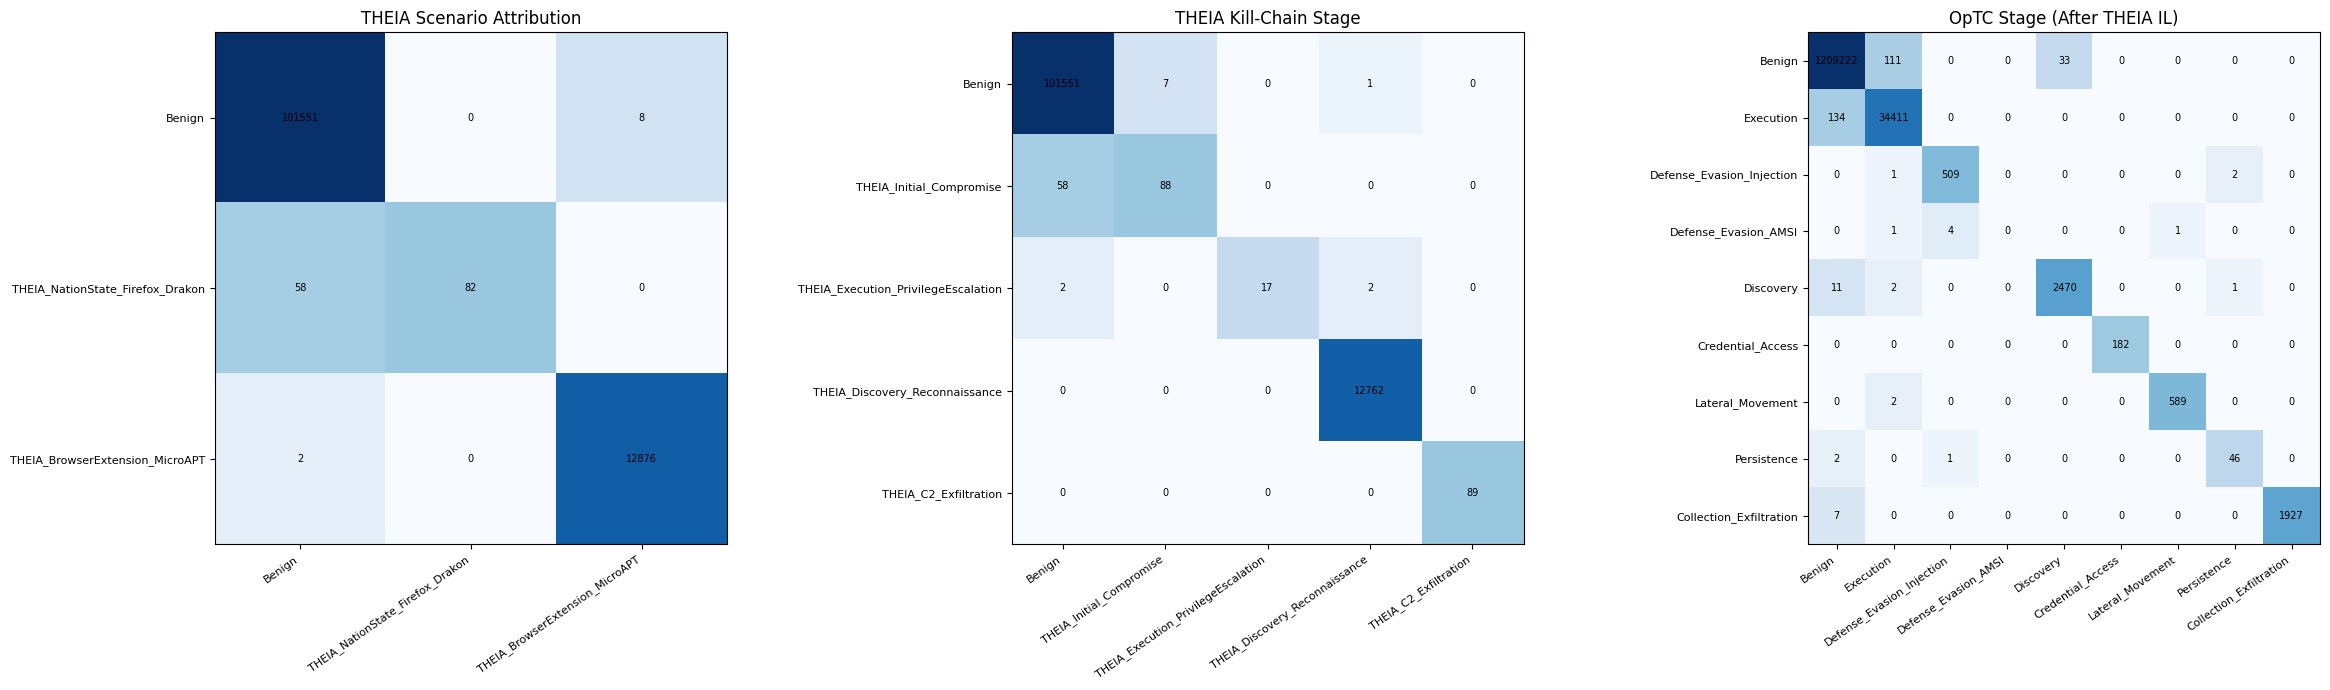


SUCCESS: Created /kaggle/working/theia_traceback_results.zip (11.67 MB) with Dual-Domain OpTC + THEIA results!


In [5]:
# Load best Joint-Val checkpoint & calibrate thresholds on VALIDATION ONLY
best_ckpt = torch.load(best_ckpt_path, map_location=device, weights_only=False)
raw_model.load_state_dict(best_ckpt["model_state_dict"])

def calibrate_val_threshold(val_loader, domain_mode: str = "theia", default_thr: float = 0.50):
    res = compute_eval_metrics(val_loader, model, domain_mode, collect_outputs=True)
    best_key = (-1.0, -1.0, -1.0)
    best_t, best_f1 = default_thr, 0.0
    for thr in [round(float(x), 4) for x in np.linspace(0.05, 0.95, 91)]:
        preds = (res["bp"] >= thr).astype(int)
        fp = int(((preds == 1) & (res["bt"] == 0)).sum())
        tn = int(((preds == 0) & (res["bt"] == 0)).sum())
        fpr = fp / max(1, fp + tn)
        f1 = f1_score(res["bt"], preds, zero_division=0)
        if fpr <= 0.01:
            key = (round(float(f1), 6), -float(fpr), -abs(float(thr) - 0.50))
            if key > best_key:
                best_key = key
                best_f1 = float(f1)
                best_t = float(thr)
    return best_t, best_f1

thr_theia, val_f1_th = calibrate_val_threshold(theia_val_loader, domain_mode="theia")
thr_optc_val, val_f1_op = calibrate_val_threshold(optc_val_loader, domain_mode="optc")
print(f"Val Calibrated Thresholds -> THEIA={thr_theia:.3f} (val F1={val_f1_th:.4f}), OpTC={thr_optc_val:.3f} (val F1={val_f1_op:.4f})")

# --- EVALUATION 1: THEIA TEST (114,577 samples) ---
th_res = compute_eval_metrics(theia_test_loader, model, "theia", collect_outputs=True)
bt_th, bp_th = th_res["bt"], th_res["bp"]
bpred_th = (bp_th >= thr_theia).astype(int)
tn_th = int(((bpred_th == 0) & (bt_th == 0)).sum())
fp_th = int(((bpred_th == 1) & (bt_th == 0)).sum())
fn_th = int(((bpred_th == 0) & (bt_th == 1)).sum())
tp_th = int(((bpred_th == 1) & (bt_th == 1)).sum())
fpr_th = fp_th / max(1, fp_th + tn_th)
p_th, r_th, f1_th, _ = precision_recall_fscore_support(bt_th, bpred_th, average="binary", zero_division=0)

print("\n=== [1/2] THEIA TEST RESULTS (Domain 2) ===")
print(f"TP={tp_th}, FP={fp_th}, TN={tn_th}, FN={fn_th} | Precision={p_th:.4f} Recall={r_th:.4f} F1={f1_th:.4f} FPR={fpr_th*100:.4f}% PR-AUC={th_res['pr_auc']:.4f} ROC-AUC={th_res['roc_auc']:.4f}")

th_sc_labels = [0, 4, 5]
th_st_labels = [0, 10, 11, 12, 13]
th_sc_rep = classification_report(th_res["sct"], th_res["scp"], labels=th_sc_labels, target_names=[UNIFIED_SCENARIO_NAMES[i] for i in th_sc_labels], output_dict=True, zero_division=0)
th_st_rep = classification_report(th_res["stt"], th_res["stp"], labels=th_st_labels, target_names=[UNIFIED_STAGE_NAMES[i] for i in th_st_labels], output_dict=True, zero_division=0)
print(classification_report(th_res["stt"], th_res["stp"], labels=th_st_labels, target_names=[UNIFIED_STAGE_NAMES[i] for i in th_st_labels], digits=4, zero_division=0))

# --- EVALUATION 2: FULL OpTC TEST (1,249,689 samples) AFTER IL + BACKWARD TRANSFER (BWT) ---
print("\n=== [2/2] FULL OpTC TEST BACKWARD TRANSFER (Domain 0: Before IL vs After IL) ===")
optc_test_after = eval_optc_test_stream(model, label="AFTER THEIA IL (Replay + Expandable + LwF)")

def summarize_optc_thr(res, thr):
    pred = (res["bp"] >= thr).astype(int)
    fp = int(((pred == 1) & (res["bt"] == 0)).sum())
    tn = int(((pred == 0) & (res["bt"] == 0)).sum())
    tp = int(((pred == 1) & (res["bt"] == 1)).sum())
    fn = int(((pred == 0) & (res["bt"] == 1)).sum())
    p, r, f1, _ = precision_recall_fscore_support(res["bt"], pred, average="binary", zero_division=0)
    return {"threshold": thr, "tp": tp, "fp": fp, "tn": tn, "fn": fn, "precision": float(p), "recall": float(r), "f1": float(f1), "fpr": float(fp / max(1, fp + tn))}

optc_after_cal = summarize_optc_thr(optc_test_after, thr_optc_val)
bwt_bin_05 = optc_test_after["at_base_thr_050"]["f1"] - optc_test_before["at_base_thr_050"]["f1"]
bwt_sc = optc_test_after["scenario_macro_f1"] - optc_test_before["scenario_macro_f1"]
bwt_st = optc_test_after["stage_macro_f1"] - optc_test_before["stage_macro_f1"]
print(f"Backward Transfer (BWT = After - Before on OpTC 1.25M Test):")
print(f"  Binary F1 @0.50 : {optc_test_before['at_base_thr_050']['f1']:.4f} -> {optc_test_after['at_base_thr_050']['f1']:.4f} (BWT={bwt_bin_05:+.4f})")
print(f"  Binary F1 @val  : {optc_after_cal['f1']:.4f} (thr={thr_optc_val:.3f}, FP={optc_after_cal['fp']}, FPR={optc_after_cal['fpr']*100:.4f}%)")
print(f"  Scenario MacroF1: {optc_test_before['scenario_macro_f1']:.4f} -> {optc_test_after['scenario_macro_f1']:.4f} (BWT={bwt_sc:+.4f})")
print(f"  Stage MacroF1   : {optc_test_before['stage_macro_f1']:.4f} -> {optc_test_after['stage_macro_f1']:.4f} (BWT={bwt_st:+.4f})")

# Plot Side-by-Side Confusion Matrices (THEIA Stage + THEIA Scenario + OpTC Stage After IL)
cm_th_sc = confusion_matrix(th_res["sct"], th_res["scp"], labels=th_sc_labels)
cm_th_st = confusion_matrix(th_res["stt"], th_res["stp"], labels=th_st_labels)
op_st_labels = sorted(set(optc_test_after["stt"].tolist()))
cm_op_st = confusion_matrix(optc_test_after["stt"], optc_test_after["stp"], labels=op_st_labels)

fig, axes = plt.subplots(1, 3, figsize=(24, 7))
for ax, cm, names, title in [
    (axes[0], cm_th_sc, [UNIFIED_SCENARIO_NAMES[i] for i in th_sc_labels], "THEIA Scenario Attribution"),
    (axes[1], cm_th_st, [UNIFIED_STAGE_NAMES[i] for i in th_st_labels], "THEIA Kill-Chain Stage"),
    (axes[2], cm_op_st, [UNIFIED_STAGE_NAMES[i].replace("OpTC_", "") for i in op_st_labels], "OpTC Stage (After THEIA IL)"),
]:
    ax.imshow(np.log1p(cm), cmap="Blues")
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels(names, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels(names, fontsize=8)
    ax.set_title(title)
    for r in range(cm.shape[0]):
        for c in range(cm.shape[1]):
            ax.text(c, r, f"{cm[r, c]}", ha="center", va="center", color="black", fontsize=7)
plt.tight_layout()
plt.savefig(WORK_DIR / "theia_confusion_matrices.png", dpi=150)
plt.show()

# Forensic Error Traceback on THEIA Test
def decode_ids(id_list):
    return [ID2TOK.get(int(i), f"<id:{i}>") for i in (id_list or [])]

def build_trace(idx, err_kind):
    s = theia_test_samples[idx]
    return {
        "test_index": int(idx),
        "error_type": err_kind,
        "event_uuid": s.get("event_uuid", ""),
        "timestamp_rec": int(s.get("timestamp_rec", 0)),
        "true_binary": int(bt_th[idx]),
        "pred_binary": int(bpred_th[idx]),
        "pred_prob": round(float(bp_th[idx]), 5),
        "true_scenario": UNIFIED_SCENARIO_NAMES.get(int(th_res["sct"][idx]), str(th_res["sct"][idx])),
        "pred_scenario": UNIFIED_SCENARIO_NAMES.get(int(th_res["scp"][idx]), str(th_res["scp"][idx])),
        "true_stage": UNIFIED_STAGE_NAMES.get(int(th_res["stt"][idx]), str(th_res["stt"][idx])),
        "pred_stage": UNIFIED_STAGE_NAMES.get(int(th_res["stp"][idx]), str(th_res["stp"][idx])),
        "E_incoming": decode_ids(s.get("incoming_ids")),
        "E_parent": decode_ids(s.get("parent_ids")),
        "E_current": decode_ids(s.get("current_ids")),
    }

fp_idx = [i for i in range(len(bt_th)) if bpred_th[i] == 1 and bt_th[i] == 0]
fn_idx = [i for i in range(len(bt_th)) if bpred_th[i] == 0 and bt_th[i] == 1]
st_err_idx = [i for i in range(len(bt_th)) if bt_th[i] == 1 and th_res["stp"][i] != th_res["stt"][i]]

with open(WORK_DIR / "theia_error_traceback.json", "w", encoding="utf-8") as f:
    json.dump({
        "threshold_theia_val": thr_theia,
        "counts": {"fp": len(fp_idx), "fn": len(fn_idx), "stage_mismatch_on_attack": len(st_err_idx)},
        "false_positives_sample": [build_trace(i, "FP") for i in fp_idx[:250]],
        "false_negatives_sample": [build_trace(i, "FN") for i in fn_idx[:250]],
        "stage_errors_sample": [build_trace(i, "STAGE_ERR") for i in st_err_idx[:250]],
    }, f, indent=2)

# Clean large numpy arrays from OpTC summary before JSON dump
optc_before_json = {k: v for k, v in optc_test_before.items() if k not in ("bp", "bt", "scp", "sct", "stp", "stt")}
optc_after_json = {k: v for k, v in optc_test_after.items() if k not in ("bp", "bt", "scp", "sct", "stp", "stt")}
optc_after_json["at_optc_val_thr"] = optc_after_cal

with open(WORK_DIR / "theia_test_metrics.json", "w", encoding="utf-8") as f:
    json.dump({
        "best_epoch": int(best_ckpt["epoch"]),
        "best_phase": best_ckpt["phase"],
        "theia": {
            "threshold_val_calibrated": thr_theia,
            "binary": {"tp": tp_th, "fp": fp_th, "tn": tn_th, "fn": fn_th, "precision": float(p_th), "recall": float(r_th), "f1": float(f1_th), "fpr": float(fpr_th), "pr_auc": th_res["pr_auc"], "roc_auc": th_res["roc_auc"]},
            "scenario_report": th_sc_rep,
            "stage_report": th_st_rep,
            "confusion_matrix_scenario": cm_th_sc.tolist(),
            "confusion_matrix_stage": cm_th_st.tolist(),
        },
        "optc_backward_transfer": {
            "before_il": optc_before_json,
            "after_il": optc_after_json,
            "confusion_matrix_stage_after_il": cm_op_st.tolist(),
            "stage_labels_after_il": [UNIFIED_STAGE_NAMES[i] for i in op_st_labels],
            "bwt": {"binary_f1_at_050": bwt_bin_05, "scenario_macro_f1": bwt_sc, "stage_macro_f1": bwt_st},
        },
        "history": history,
        "manifest": MANIFEST,
    }, f, indent=2)

zip_out = WORK_DIR / "theia_traceback_results.zip"
bundle_files = [
    WORK_DIR / "theia_mixhead_il_best.pt",
    WORK_DIR / "theia_test_metrics.json",
    WORK_DIR / "theia_error_traceback.json",
    WORK_DIR / "theia_confusion_matrices.png",
]
with zipfile.ZipFile(zip_out, "w", zipfile.ZIP_DEFLATED, compresslevel=6) as zf:
    for bf in bundle_files:
        if bf.is_file():
            zf.write(bf, arcname=bf.name)
assert zip_out.is_file() and zip_out.stat().st_size > 0
print(f"\nSUCCESS: Created {zip_out} ({zip_out.stat().st_size / (1024*1024):.2f} MB) with Dual-Domain OpTC + THEIA results!")